In [ ]:
"""
ComfyUI Image Generation with Google ADK
Clean notebook using agents/comfy module

Dependencies: See requirements.txt
Run `pip install -r requirements.txt` if imports fail.
"""

import sys
import os
import logging
from pathlib import Path

# Add project root to path - handle different Jupyter start locations
# Works both in Docker container (/home/jovyan/workspace) and host system
cwd = Path.cwd()

# Try common locations for the workspace
possible_roots = [
    cwd,  # Current directory
    cwd.parent,  # Parent directory (if in notebooks/)
    cwd / "workspace",  # If CWD is /home/jovyan, workspace is subdir
    Path("/home/jovyan/workspace"),  # Docker container mount point
    Path("/home/warby/Workspace/jupyter"),  # Host system path
]

project_root = None
for root in possible_roots:
    if root.exists() and (root / "agents").exists():
        project_root = root
        break

if project_root is None:
    # Last resort: try to find it by searching up the directory tree
    current = cwd
    for _ in range(5):  # Search up to 5 levels
        if (current / "agents").exists():
            project_root = current
            break
        current = current.parent

if project_root is None:
    raise RuntimeError(
        f"Could not find project root with 'agents' directory. "
        f"Current dir: {cwd}, Checked: {possible_roots}"
    )

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print(f"Project root: {project_root}")
print(f"Agents module path: {project_root / 'agents'}")

# Load environment variables from .env file
# Try multiple possible locations
from dotenv import load_dotenv
env_paths = [
    project_root / ".env",  # Project root .env
    Path.home() / "workspace" / ".env",  # Docker container default
    Path("/home/jovyan/workspace/.env"),  # Absolute Docker path
]

env_loaded = False
for env_path in env_paths:
    if env_path.exists():
        load_dotenv(env_path, override=True)
        print(f"Loaded environment from: {env_path}")
        env_loaded = True
        break

if not env_loaded:
    print("Warning: No .env file found. Environment variables may not be set.")

# Silence LiteLLM debug output and suppress provider list messages
import litellm
import sys
import io
from contextlib import redirect_stderr

litellm.set_verbose = False
logging.getLogger("LiteLLM").setLevel(logging.ERROR)  # Set to ERROR to suppress more messages

# Suppress litellm stderr output (provider list messages)
class SuppressLiteLLMStderr:
    """Context manager to suppress litellm stderr output."""
    def __init__(self):
        self.original_stderr = sys.stderr
        self.null_stderr = io.StringIO()
    
    def __enter__(self):
        sys.stderr = self.null_stderr
        return self
    
    def __exit__(self, *args):
        sys.stderr = self.original_stderr

# Store the suppressor for use in tools
_suppress_litellm = SuppressLiteLLMStderr()

print("Environment configured")

Project root: /home/jovyan/workspace
Agents module path: /home/jovyan/workspace/agents
Loaded environment from: /home/jovyan/workspace/.env
Environment configured


Agent imported successfully
  Agent name: comfyui_image_generator
  Sub-agents: 0 (should be 0)
  Tools: 4 (should be 4)
✅ Agent configuration correct - no sub-agents

User Request: A cyberpunk gopher astronaut floating in space, digital art


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers



13:49:45 [INFO] comfy.agents.comfy.tools: Enhancing prompt: A cyberpunk gopher astronaut floating in space, di...



Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers



13:49:47 [INFO] comfy.agents.comfy.tools: Prompt enhanced successfully



Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers

[Event 2] Tool result: enhance_prompt
  Result: {'result': "A sleek, chrome-plated gopher astronaut, adorned with intricate neon circuit patterns...

Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers



...

[Event 4] Tool result: select_workflow
  Result: {'workflow_name': None, 'reasoning': 'Using proven programmatic Z-Image Turbo workflow from img_z...

Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers



13:49:49 [INFO] comfy.agents.comfy.tools: Starting image generation with workflow: None
13:49:49 [INFO] comfy.agents.comfy.tools: Using programmatic Z-Image Turbo workflow
13:49:49 [INFO] comfy.agents.comfy.tools: Submitting to RunPod (endpoint: a48mrbdsbzg35n)
13:49:49 [INFO] comfy.agents.comfy.tools: Prompt: A sleek, chrome-plated gopher astronaut, adorned with intricate neon circuit patterns that glow with...
13:49:49 [INFO] comfy.agents.comfy.tools: Seed: 1370700282
13:49:49 [INFO] comfy.agents.comfy.tools: Job submitted: 8f60a793-281e-4ebb-8e1d-7642b26d7f74-u2
13:49:49 [INFO] comfy.agents.comfy.tools: Polling for completion (max 10 minutes)...


[INIT] RunPod runner initialized with endpoint: a48mrbdsbzg35n
[SUBMIT] Sending request to RunPod...
[OK] Job started with ID: 8f60a793-281e-4ebb-8e1d-7642b26d7f74-u2
[POLL] Checking job status (timeout: 600s)...


13:50:00 [INFO] comfy.agents.comfy.tools: Generation completed, processing image...
13:50:00 [INFO] comfy.agents.comfy.tools: Image saved: /home/jovyan/workspace/outputs/comfyui_1765137000_1370700282.png
13:50:00 [INFO] comfy.agents.comfy.tools: Generation complete! Elapsed: 0.0s


[OK] Job completed successfully!
[Event 6] Tool result: generate_image_with_runpod
  ✅ Image generated: /home/jovyan/workspace/outputs/comfyui_1765137000_1370700282.png

Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers

[Event 7] Text: The image has been generated: /home/jovyan/workspace/outputs/comfyui_1765137000_1370700282.png

Agent Final Response:
The image has been generated: /home/jovyan/workspace/outputs/comfyui_1765137000_1370700282.png


✅ Image generated successfully!
📁 Filepath: /home/jovyan/workspace/outputs/comfyui_1765137000_1370700282.png


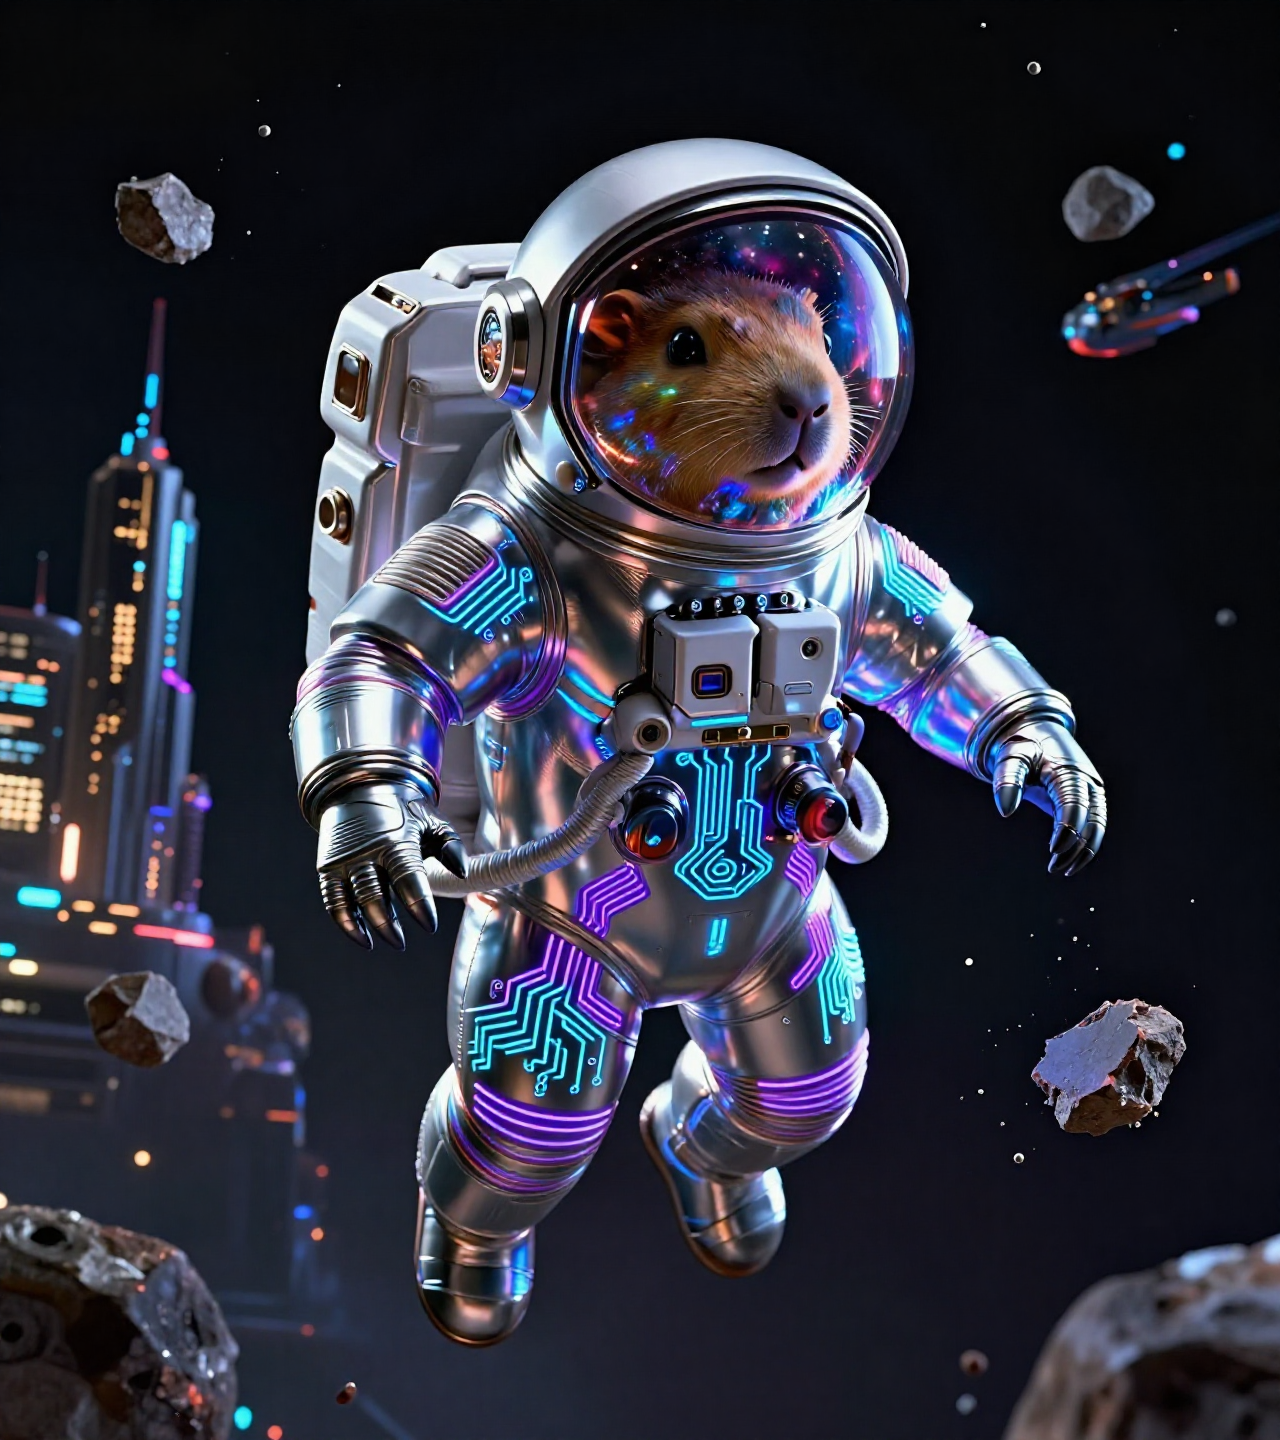


Provider List: https://docs.litellm.ai/docs/providers


Provider List: https://docs.litellm.ai/docs/providers



In [ ]:
"""
Import and run the ComfyUI image generation agent with enhanced debugging
"""

import asyncio
import re
from pathlib import Path
from IPython.display import display, Image, HTML
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.genai import types

# Import the root agent from our module
# IMPORTANT: If you see "Sub-agents: 2" or the agent tries to transfer_to_agent,
# you need to RESTART THE KERNEL to reload the updated agent configuration.
from agents.comfy import root_agent

print("Agent imported successfully")
print(f"  Agent name: {root_agent.name}")
print(f"  Sub-agents: {len(root_agent.sub_agents)} (should be 0)")
print(f"  Tools: {len(root_agent.tools)} (should be 4)")

if len(root_agent.sub_agents) > 0:
    print("\n[WARNING] Agent has sub-agents! Restart kernel to reload.")
    print("   Go to: Kernel → Restart Kernel")
else:
    print("[INFO] Agent configuration correct - no sub-agents")


def display_generated_image(filepath: str):
    """Display a generated image in the notebook."""
    try:
        path = Path(filepath)
        if path.exists():
            print(f"\n[INFO] Image generated successfully")
            print(f"[INFO] Filepath: {filepath}")
            display(Image(filename=str(path), width=800))
        else:
            print(f"[WARNING] Image file not found: {filepath}")
    except Exception as e:
        print(f"[WARNING] Failed to display image: {e}")


def extract_filepath_from_response(response_text: str) -> str:
    """Extract filepath from agent response text."""
    # Look for filepath in the response
    patterns = [
        r'filepath["\']?\s*:\s*["\']([^"\']+)["\']',  # JSON-like
        r'outputs/[^"\s]+\.png',  # Direct path mention
        r'saved:\s*([^\s]+\.png)',  # "saved: path/to/file.png"
    ]
    
    for pattern in patterns:
        match = re.search(pattern, response_text, re.IGNORECASE)
        if match:
            if pattern == r'outputs/[^"\s]+\.png':
                return match.group(0)
            else:
                return match.group(1)
    
    return None


async def generate_image(prompt: str, show_intermediate: bool = True):
    """
    Generate an image using the ComfyUI agent.
    
    The agent will:
    1. Enhance your prompt using Z-Image Turbo methodology
    2. Select appropriate workflow
    3. Generate the image
    4. Report results
    
    Args:
        prompt: User prompt for image generation
        show_intermediate: If True, show intermediate agent events
    """
    # Create session
    session_service = InMemorySessionService()
    await session_service.create_session(
        user_id="demo_user",
        session_id="demo_session",
        app_name="comfyui_gen"
    )
    
    # Create runner
    runner = Runner(
        agent=root_agent,
        app_name="comfyui_gen",
        session_service=session_service
    )
    
    # Prepare user message
    content = types.Content(
        role="user",
        parts=[types.Part(text=prompt)]
    )
    
    # Run agent
    print(f"\n{'='*60}")
    print(f"User Request: {prompt}")
    print(f"{'='*60}\n")
    
    final_response = None
    generated_filepath = None
    event_count = 0
    
    # Suppress stderr during agent execution to hide litellm provider list messages
    import sys
    import io
    original_stderr = sys.stderr
    
    try:
        # Redirect stderr to suppress litellm provider list messages
        sys.stderr = io.StringIO()
        
        async for event in runner.run_async(
            user_id="demo_user",
            session_id="demo_session",
            new_message=content
        ):
            event_count += 1
            
            # Extract tool call results from event
            if hasattr(event, 'content') and event.content:
                if hasattr(event.content, 'parts') and event.content.parts:
                    for part in event.content.parts:
                        # Check for function_response (tool result)
                        if hasattr(part, 'function_response') and part.function_response:
                            function_response = part.function_response
                            function_name = getattr(function_response, 'name', 'unknown')
                            response_data = getattr(function_response, 'response', None)
                            
                            if show_intermediate:
                                print(f"[Event {event_count}] Tool result: {function_name}")
                            
                            # Check if this is the generate_image_with_runpod result
                            if function_name == "generate_image_with_runpod" and response_data:
                                # response_data should be a dict with status, filepath, etc.
                                if isinstance(response_data, dict):
                                    status = response_data.get('status')
                                    if status == 'success':
                                        filepath = response_data.get('filepath')
                                        if filepath:
                                            generated_filepath = filepath
                                            if show_intermediate:
                                                print(f"  [INFO] Image generated: {filepath}")
                                    else:
                                        error_msg = response_data.get('message', 'Unknown error')
                                        if show_intermediate:
                                            print(f"  [ERROR] Image generation failed: {error_msg}")
                            
                            # Show other tool results (truncated)
                            elif show_intermediate and response_data:
                                response_str = str(response_data)
                                if len(response_str) > 100:
                                    response_str = response_str[:97] + "..."
                                print(f"  Result: {response_str}")
                        
                        # Show text responses
                        if hasattr(part, 'text') and part.text:
                            if show_intermediate:
                                text_preview = part.text[:150] + "..." if len(part.text) > 150 else part.text
                                print(f"[Event {event_count}] Text: {text_preview}")
            
            # Check for final response
            if event.is_final_response():
                if hasattr(event, 'content') and event.content:
                    if hasattr(event.content, 'parts') and event.content.parts:
                        # Get text from final response
                        for part in event.content.parts:
                            if hasattr(part, 'text') and part.text:
                                final_response = part.text
                                break
                
                if final_response:
                    print(f"\n{'='*60}")
                    print("Agent Final Response:")
                    print(f"{'='*60}")
                    print(final_response)
                    print(f"{'='*60}\n")
                break
        
        # Restore stderr
        sys.stderr = original_stderr
        
        # Display image if we found a filepath from tool results
        if generated_filepath:
            display_generated_image(generated_filepath)
        elif final_response:
            # Fallback: try to extract from text response
            filepath = extract_filepath_from_response(final_response)
            if filepath:
                display_generated_image(filepath)
            else:
                print("[INFO] No image filepath found in tool results or response text")
        else:
            print("[WARNING] No final response received and no image filepath found")
        
        return {
            'response': final_response,
            'filepath': generated_filepath
        }
        
    except Exception as e:
        # Restore stderr before printing error
        sys.stderr = original_stderr
        print(f"\n[ERROR] {e}")
        import traceback
        traceback.print_exc()
        return None
    finally:
        # Ensure stderr is always restored
        sys.stderr = original_stderr


# Demo: Generate a test image with debug output
result = await generate_image(
    "A cyberpunk gopher astronaut floating in space, digital art",
    show_intermediate=True
)

# ComfyUI Agent - Usage Guide

## Quick Reference

### Enable Debug Mode
```bash
# Set environment variable before starting Jupyter
export COMFY_DEBUG=1
```

### Generate Images
```python
# Simple generation
result = await generate_image("Your prompt here")

# Without intermediate output
result = await generate_image("Your prompt here", show_intermediate=False)
```

### Display Saved Images
```python
from pathlib import Path
from IPython.display import Image, display

# Display a specific image
image_path = "outputs/comfyui_1234567890_12345.png"
display(Image(filename=image_path, width=800))
```

## Agent Architecture

- **Root Agent** (`comfyui_image_generator`): Orchestrates the full workflow
- **Sub-Agent 1** (`zit_prompt_enhancer`): Enhances prompts using Z-Image Turbo
- **Sub-Agent 2** (`workflow_selector`): Selects appropriate ComfyUI workflow
- **Tools**: `generate_image_with_runpod`, `list_workflows`

## Testing

Run tests from project root:
```bash
# All tests
pytest agents/comfy/tests/

# Unit tests only
pytest agents/comfy/tests/ -m unit

# Integration tests (slower, requires API keys)
pytest agents/comfy/tests/ -m integration

# Specific test file
pytest agents/comfy/tests/test_prompts.py -v
```

## Debug Logging

When `COMFY_DEBUG=1` is set, you'll see:
- Timing information for each step
- RunPod job submission details
- Completion messages
- Final generation summary

## DevOps Hooks

See `agents/comfy/callbacks.py` for integrating with monitoring systems:
- `LoggingCallback`: Structured JSON logging
- `MetricsCallback`: Prometheus-compatible metrics
- `FileLoggingCallback`: Audit trail logging
